<a href="https://colab.research.google.com/github/AlvinManoj05/Parallel_project_Computer_Vision/blob/main/Parallel_Project__computerVision_PneumoniaDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

01_Dataset_Exploration_and_Preprocessing-Ananthika

Import Libraries

In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
from google.colab import drive


In [ ]:
dataset_path = "https://github.com/AlvinManoj05/Parallel_project_Computer_Vision/tree/main/xray_dataset_covid19"

print("Dataset exists:", os.path.exists(dataset_path))
print("Available folders:", os.listdir(dataset_path))


Dataset exists: True
Available folders: ['single prediction', 'train', 'test']


In [ ]:
#Count the images

classes = ["NORMAL", "PNEUMONIA"]

for split in ["train", "test"]:
    print(f"\n{split.upper()} DATASET")

    for class_name in classes:
        folder = os.path.join(dataset_path, split, class_name)

        images = [
            file for file in os.listdir(folder)
            if file.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(f"{class_name}: {len(images)} images")



TRAIN DATASET
NORMAL: 74 images
PNEUMONIA: 74 images

TEST DATASET
NORMAL: 20 images
PNEUMONIA: 20 images


Dataset Exploration – Image Visualization

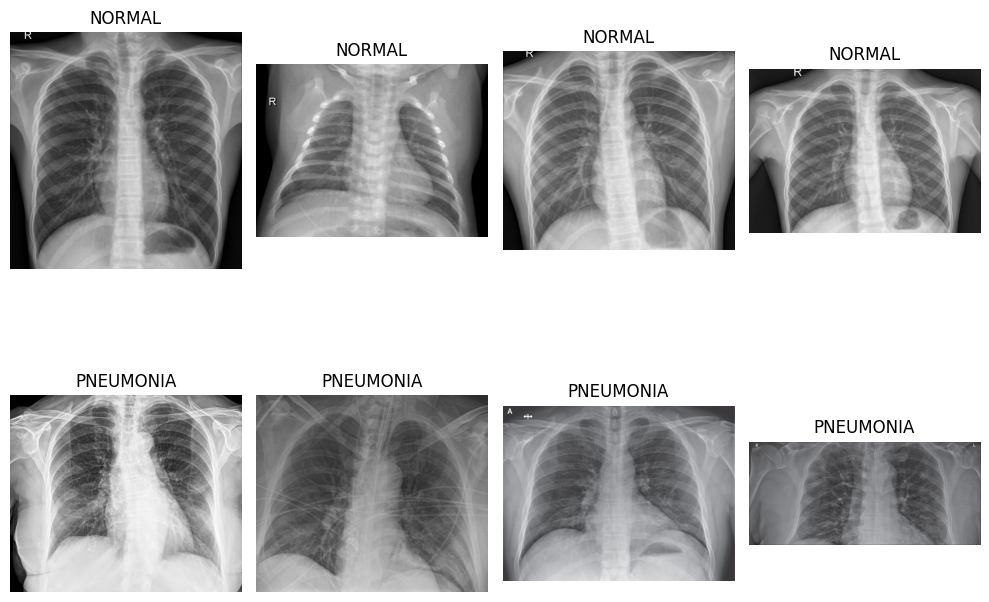

In [ ]:
#Display NORMAL and PNEUMONIA images
classes = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(classes):
    folder = os.path.join(dataset_path, "train", class_name)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    sample_images = random.sample(image_files, min(4, len(image_files)))

    for j, image_name in enumerate(sample_images):
        image_path = os.path.join(folder, image_name)
        image = mpimg.imread(image_path)

        plt.subplot(2, 4, i * 4 + j + 1)
        plt.imshow(image, cmap="gray")
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
#Image dimensions and formats
image_data = []

classes = ["NORMAL", "PNEUMONIA"]

for class_name in classes:
    folder = os.path.join(dataset_path, "train", class_name)

    for filename in os.listdir(folder):
        image_path = os.path.join(folder, filename)

        try:
            with Image.open(image_path) as img:
                image_data.append({
                    "Class": class_name,
                    "Filename": filename,
                    "Width": img.width,
                    "Height": img.height,
                    "Format": img.format,
                    "Mode": img.mode
                })

        except Exception as e:
            print("Error:", filename, e)

df = pd.DataFrame(image_data)

print("Total images inspected:", len(df))
print("\nImage dimensions:")
print(df[["Width", "Height"]].describe())

print("\nImage formats:")
print(df["Format"].value_counts())

print("\nImage modes:")
print(df["Mode"].value_counts())


Total images inspected: 148

Image dimensions:
             Width       Height
count   148.000000   148.000000
mean   1697.527027  1385.479730
std     767.623698   693.882888
min     255.000000   237.000000
25%    1246.750000   875.500000
50%    1790.500000  1376.500000
75%    2060.250000  1757.250000
max    4248.000000  4095.000000

Image formats:
Format
JPEG    136
PNG      12
Name: count, dtype: int64

Image modes:
Mode
L       81
RGB     56
RGBA    11
Name: count, dtype: int64


In [ ]:
#Check for corrupted images
corrupted_images = []
checked_images = 0

for split in ["train", "test"]:
    for class_name in classes:

        folder = os.path.join(dataset_path, split, class_name)

        for filename in os.listdir(folder):
            image_path = os.path.join(folder, filename)

            try:
                with Image.open(image_path) as img:
                    img.verify()

                checked_images += 1

            except Exception:
                corrupted_images.append(image_path)

print("Images checked:", checked_images)
print("Corrupted images:", len(corrupted_images))
print("\nCorrupted file paths:")
print(corrupted_images)


Images checked: 188
Corrupted images: 0

Corrupted file paths:
[]


Train-validation split

In [ ]:

image_paths = []
labels = []

class_names = ["NORMAL", "PNEUMONIA"]

for label, class_name in enumerate(class_names):

    folder = os.path.join(dataset_path, "train", class_name)

    for filename in os.listdir(folder):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            image_paths.append(os.path.join(folder, filename))
            labels.append(label)

# Split training data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))

print("\nTraining class distribution:")
for label, class_name in enumerate(class_names):
    print(class_name, ":", y_train.count(label))

print("\nValidation class distribution:")
for label, class_name in enumerate(class_names):
    print(class_name, ":", y_val.count(label))


Training images: 118
Validation images: 30

Training class distribution:
NORMAL : 59
PNEUMONIA : 59

Validation class distribution:
NORMAL : 15
PNEUMONIA : 15


Image resizing and normalization

In [ ]:
IMG_SIZE = 224

def preprocess_images(image_paths):
    images = []

    for path in image_paths:
        img = Image.open(path).convert("L")
        img = img.resize((IMG_SIZE, IMG_SIZE))

        img_array = np.array(img, dtype=np.float32) / 255.0

        images.append(img_array)

    images = np.array(images)
    images = np.expand_dims(images, axis=-1)

    return images

# Preprocess training and validation images
X_train_processed = preprocess_images(X_train)
X_val_processed = preprocess_images(X_val)

# Convert labels into NumPy arrays
y_train = np.array(y_train, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)

print("Minimum pixel value:", X_train_processed.min())
print("Maximum pixel value:", X_train_processed.max())


Training shape: (118, 224, 224, 1)
Validation shape: (30, 224, 224, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


Visualize preprocessed images

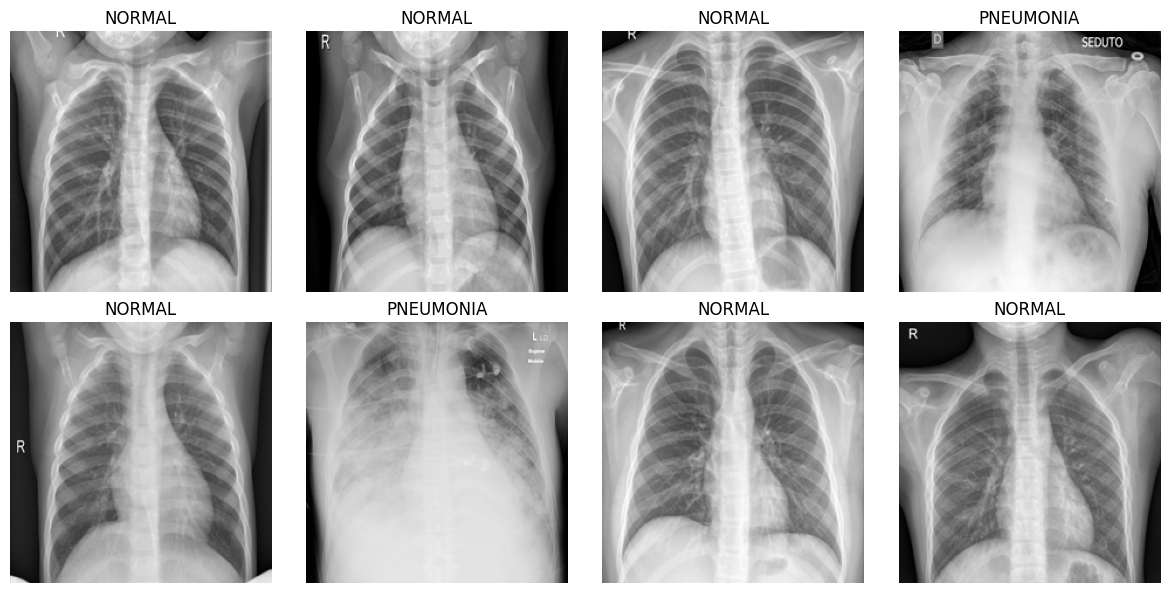

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    plt.imshow(X_train_processed[i].squeeze(), cmap="gray")

    label = class_names[int(y_train[i])]
    plt.title(label)

    plt.axis("off")

plt.tight_layout()
plt.show()


Preprocess test images

In [ ]:
test_paths = []
test_labels = []

class_names = ["NORMAL", "PNEUMONIA"]

for label, class_name in enumerate(class_names):

    folder = os.path.join(dataset_path, "test", class_name)

    for filename in os.listdir(folder):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            test_paths.append(os.path.join(folder, filename))
            test_labels.append(label)

# Preprocess test images
X_test_processed = preprocess_images(test_paths)

y_test = np.array(test_labels, dtype=np.float32)

print("Test images:", len(X_test_processed))
print("Test shape:", X_test_processed.shape)

print("\nTest class distribution:")

for i, name in enumerate(class_names):
    print(name, ":", np.sum(y_test == i))


Test images: 40
Test shape: (40, 224, 224, 1)

Test class distribution:
NORMAL : 20
PNEUMONIA : 20


Verify all datasets

In [ ]:
print("FINAL DATASET SHAPES")

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

print("\nLabel shapes")

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)


FINAL DATASET SHAPES
Training: (118, 224, 224, 1)
Validation: (30, 224, 224, 1)
Testing: (40, 224, 224, 1)

Label shapes
Training labels: (118,)
Validation labels: (30,)
Testing labels: (40,)


Convert images into TensorFlow datasets

In [ ]:
BATCH_SIZE = 16

# Training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_processed, y_train)
)

train_dataset = (
    train_dataset
    .shuffle(buffer_size=len(X_train_processed), seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_processed, y_val)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Testing dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test_processed, y_test)
)

test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("TensorFlow datasets created successfully!")

print("Training batches:", len(train_dataset))
print("Validation batches:", len(val_dataset))
print("Testing batches:", len(test_dataset))


TensorFlow datasets created successfully!
Training batches: 8
Validation batches: 2
Testing batches: 3


In [ ]:
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())


Image batch shape: (16, 224, 224, 1)
Label batch shape: (16,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
save_path = "/content/preprocessed_data"
os.makedirs(save_path, exist_ok=True)

np.save(save_path + "/X_train.npy", X_train_processed)
np.save(save_path + "/y_train.npy", y_train)
np.save(save_path + "/X_val.npy", X_val_processed)
np.save(save_path + "/y_val.npy", y_val)
np.save(save_path + "/X_test.npy", X_test_processed)
np.save(save_path + "/y_test.npy", y_test)

print("Saved inside Colab successfully!")

Saved inside Colab successfully!


##Model Development-CNN-Anjima



**Import libraries**


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [ ]:
#check input data
print("Training images:", X_train_processed.shape)
print("Validation images:", X_val_processed.shape)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

Training images: (118, 224, 224, 1)
Validation images: (30, 224, 224, 1)
Training labels: (118,)
Validation labels: (30,)


In [ ]:
#check shape of test images and test labels
print("Test images:", X_test_processed.shape)
print("Test labels:", y_test.shape)

Test images: (40, 224, 224, 1)
Test labels: (40,)


**CNN Model**

In [ ]:
cnn_model = models.Sequential([
layers.Input(shape=(224, 224, 1)),
layers.Conv2D(32, (3,3), activation='relu', padding='same'),
layers.MaxPooling2D(2,2),

layers.Conv2D(64, (3,3), activation='relu', padding='same'),
layers.MaxPooling2D(2,2),

layers.Conv2D(128, (3,3), activation='relu', padding='same'),
layers.MaxPooling2D(2,2),

layers.GlobalAveragePooling2D(),

layers.Dense(128, activation='relu'),

layers.Dropout(0.5),

layers.Dense(1, activation='sigmoid')])

cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,313 (427.00 KB)

 Trainable params: 109,313 (427.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#compile the model
cnn_model.compile(optimizer='adam',loss='binary_crossentropy',metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')])

In [ ]:
#train the model
early_stop_cnn = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)
cnn_history = cnn_model.fit(
 X_train_processed,y_train,
validation_data=(X_val_processed, y_val),epochs=20,batch_size=16,callbacks=[early_stop_cnn])

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 734ms/step - accuracy: 0.5085 - auc: 0.4454 - loss: 0.7011 - precision: 0.5714 - recall: 0.0678 - val_accuracy: 0.5000 - val_auc: 0.3422 - val_loss: 0.6956 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.5085 - auc: 0.5419 - loss: 0.6909 - precision: 0.5116 - recall: 0.3729 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_loss: 0.6928 - val_precision: 0.5000 - val_recall: 1.0000
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4322 - auc: 0.4262 - loss: 0.6958 - precision: 0.4412 - recall: 0.5085 - val_accuracy: 0.5000 - val_auc: 0.8667 - val_loss: 0.6924 - val_precision: 0.5000 - val_recall: 1.0000
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.4237 - auc: 0.4091 - loss: 0.6971 - precision: 0.4400 - recall: 0.5593 - val_accuracy: 0.5000 - val_auc: 0.9000 - val_loss: 0.6916 - val_precision: 0.5000 - val_recall: 1.0000
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━

In [ ]:
#save the model
cnn_model.save("custom_cnn.keras")

# finetuning cnn - dhevan


In [ ]:
# ==========================================
# CUSTOM CNN FINE-TUNING
# ==========================================

# Load the saved baseline Custom CNN model
cnn_finetuned = tf.keras.models.load_model("custom_cnn.keras")

# Optional: Freeze the first convolutional block (Conv2D + MaxPooling2D)
# and fine-tune the deeper layers. Comment out these 2 lines to train all layers.
for layer in cnn_finetuned.layers[:2]:
    layer.trainable = False

# Recompile with a much lower learning rate for fine-tuning
cnn_finetuned.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)

cnn_finetuned.summary()

NameError: name 'tf' is not defined

In [ ]:
early_stop_cnn_ft = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

reduce_lr_cnn_ft = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
)

cnn_finetune_history = cnn_finetuned.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=15,
    batch_size=16,
    callbacks=[early_stop_cnn_ft, reduce_lr_cnn_ft],
)

# Save the fine-tuned Custom CNN
cnn_finetuned.save("custom_cnn_finetuned.keras")
print("Fine-tuned Custom CNN saved successfully!")

In [ ]:
# Evaluate on test data
ft_cnn_results = cnn_finetuned.evaluate(
    X_test_processed,
    y_test,
    batch_size=16,
    verbose=1,
)

print("\nFINE-TUNED CUSTOM CNN TEST RESULTS")
for name, value in zip(cnn_finetuned.metrics_names, ft_cnn_results):
    print(f"{name}: {value:.4f}")

# Generate predictions and classification report
ft_cnn_prob = cnn_finetuned.predict(X_test_processed)
ft_cnn_pred = (ft_cnn_prob > 0.5).astype(int).flatten()

print("\nFINE-TUNED CUSTOM CNN CLASSIFICATION REPORT")
print(
    classification_report(
        y_test.astype(int),
        ft_cnn_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4,
    )
)

#Model development-Transfer learning-Ashwathy

**Transfer Learning-ResNet-50**

In [ ]:
base_model = ResNet50(weights='imagenet',include_top=False,input_shape=(224, 224, 3))
base_model.trainable = False

In [ ]:
#adding classification layers
inputs = layers.Input(shape=(224, 224, 1))
# Convert grayscale to 3 channels
x = layers.Lambda(lambda img: tf.image.grayscale_to_rgb(img))(inputs)
# Convert pixel values from 0-1 to 0-255
x = layers.Rescaling(255.0)(x)
# Apply ResNet50 preprocessing
x = layers.Lambda(preprocess_input)(x)
# Extract image features
x = base_model(x, training=False)
# Classification layers
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
transfer_model = models.Model(inputs, outputs)
transfer_model.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_4 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_5 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
#compile the model
transfer_model.compile(
optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
loss='binary_crossentropy',metrics=['accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')])

In [ ]:
#train the model
early_stop_transfer = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)
transfer_history = transfer_model.fit(X_train_processed,y_train,
validation_data=(X_val_processed, y_val),epochs=10,batch_size=16,
callbacks=[early_stop_transfer])

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.5000 - auc: 0.4954 - loss: 0.9222 - precision: 0.5000 - recall: 0.5424 - val_accuracy: 0.7667 - val_auc: 0.9733 - val_loss: 0.4949 - val_precision: 1.0000 - val_recall: 0.5333
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.7542 - auc: 0.8482 - loss: 0.5070 - precision: 0.8750 - recall: 0.5932 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.2711 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.8983 - auc: 0.9543 - loss: 0.3012 - precision: 0.8983 - recall: 0.8983 - val_accuracy: 0.9667 - val_auc: 1.0000 - val_loss: 0.1971 - val_precision: 0.9375 - val_recall: 1.0000
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - accuracy: 0.9237 - auc: 0.9706 - loss: 0.2680 - precision: 0.9032 - recall: 0.9492 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1430 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/s

In [ ]:
#save the model
transfer_model.save("resnet50_transfer.keras")

**Finetuning**

In [ ]:
base_model.trainable = True
# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False
# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [ ]:
#recompile the model
transfer_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),loss='binary_crossentropy',
metrics=['accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')])

#Model Evaluation and Testing- Gautham Hari

In [ ]:


# 45. RESNET50 FINE-TUNING TRAINING


early_stop_finetune = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

finetune_history = transfer_model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=10,
    batch_size=16,
    callbacks=[early_stop_finetune, reduce_lr]
)


Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.9661 - auc: 0.9986 - loss: 0.0840 - precision: 0.9661 - recall: 0.9661 - val_accuracy: 0.9667 - val_auc: 1.0000 - val_loss: 0.0579 - val_precision: 0.9375 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - accuracy: 0.9915 - auc: 1.0000 - loss: 0.0421 - precision: 0.9833 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0536 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0179 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9667 - val_auc: 1.0000 - val_loss: 0.0423 - val_precision: 0.9375 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0057 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9667 - val_auc: 1.0000 - val_loss: 0.0375 - val

In [ ]:


# 46. SAVE FINAL FINE-TUNED MODEL


transfer_model.save("resnet50_finetuned.keras")

print("Fine-tuned ResNet50 model saved successfully!")


Fine-tuned ResNet50 model saved successfully!


In [ ]:


# 47. MODEL EVALUATION ON TEST DATA


test_results = transfer_model.evaluate(
    X_test_processed,
    y_test,
    batch_size=16,
    verbose=1
)

print("\nRESNET50 TEST RESULTS")

for metric_name, metric_value in zip(
    transfer_model.metrics_names,
    test_results
):
    print(f"{metric_name}: {metric_value:.4f}")


3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.9750 - auc: 1.0000 - loss: 0.0291 - precision: 1.0000 - recall: 0.9500

RESNET50 TEST RESULTS
loss: 0.0291
compile_metrics: 0.9750


In [ ]:


# 48. PREDICT ON TEST DATA


y_pred_prob = transfer_model.predict(X_test_processed)

# Convert probabilities into binary predictions
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

y_true = y_test.astype(int)

print("Predictions generated successfully!")

print("Actual labels:", y_true[:10])
print("Predicted labels:", y_pred[:10])
print("Prediction probabilities:", y_pred_prob[:10].flatten())


2/2 ━━━━━━━━━━━━━━━━━━━━ 7s 4s/step
Predictions generated successfully!
Actual labels: [0 0 0 0 0 0 0 0 0 0]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]
Prediction probabilities: [2.4461170e-04 5.0533540e-04 7.1847593e-05 7.6348038e-04 4.3077227e-05
 9.4635630e-05 4.7247335e-03 3.4460347e-02 2.0268561e-05 1.1826917e-02]


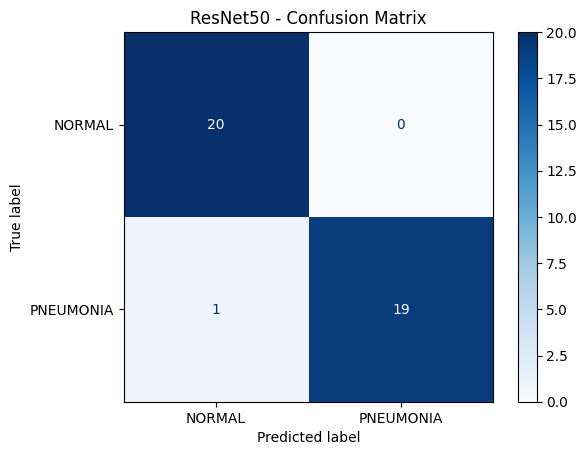

Confusion Matrix:
[[20  0]
 [ 1 19]]


In [ ]:

# ==========================================
# 49. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("ResNet50 - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)


In [ ]:

# ==========================================
# 50. CLASSIFICATION REPORT
# ==========================================

print("RESNET50 CLASSIFICATION REPORT")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    )
)


RESNET50 CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL     0.9524    1.0000    0.9756        20
   PNEUMONIA     1.0000    0.9500    0.9744        20

    accuracy                         0.9750        40
   macro avg     0.9762    0.9750    0.9750        40
weighted avg     0.9762    0.9750    0.9750        40



In [ ]:

# ==========================================
# 51. TEST DATASET INFORMATION
# ==========================================

print("Total test images:", len(y_test))

print("\nClass distribution:")

for i, name in enumerate(class_names):
    print(name, ":", np.sum(y_test == i))

print("\nCorrect predictions:", np.sum(y_true == y_pred))
print("Incorrect predictions:", np.sum(y_true != y_pred))


Total test images: 40

Class distribution:
NORMAL : 20
PNEUMONIA : 20

Correct predictions: 39
Incorrect predictions: 1


In [ ]:

# ==========================================
# 55. CUSTOM CNN MODEL EVALUATION
# ==========================================

cnn_results = cnn_model.evaluate(
    X_test_processed,
    y_test,
    batch_size=16,
    verbose=1
)

print("\nCUSTOM CNN TEST RESULTS")

for name, value in zip(
    cnn_model.metrics_names,
    cnn_results
):
    print(f"{name}: {value:.4f}")


3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.9750 - auc: 1.0000 - loss: 0.2084 - precision: 1.0000 - recall: 0.9500

CUSTOM CNN TEST RESULTS
loss: 0.2084
compile_metrics: 0.9750


In [ ]:

# ==========================================
# 56. CUSTOM CNN PREDICTIONS
# ==========================================

cnn_pred_prob = cnn_model.predict(X_test_processed)

cnn_pred = (cnn_pred_prob > 0.5).astype(int).flatten()

print("CNN predictions generated successfully!")

print("Actual labels:", y_test[:10])
print("Predicted labels:", cnn_pred[:10])


1/2 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 736ms/step
CNN predictions generated successfully!
Actual labels: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]


In [ ]:

# ==========================================
# 56. CUSTOM CNN PREDICTIONS
# ==========================================

cnn_pred_prob = cnn_model.predict(X_test_processed)

cnn_pred = (cnn_pred_prob > 0.5).astype(int).flatten()

print("CNN predictions generated successfully!")

print("Actual labels:", y_test[:10])
print("Predicted labels:", cnn_pred[:10])


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
CNN predictions generated successfully!
Actual labels: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Predicted labels: [0 0 0 0 0 0 0 0 0 0]


In [ ]:

# ==========================================
# 57. CUSTOM CNN PERFORMANCE METRICS
# ==========================================

cnn_accuracy = accuracy_score(y_true, cnn_pred)

cnn_precision = precision_score(y_true, cnn_pred)
cnn_recall = recall_score(y_true, cnn_pred)
cnn_f1 = f1_score(y_true, cnn_pred)

cnn_auc = roc_auc_score(
    y_true,
    cnn_pred_prob.flatten()
)

print("CUSTOM CNN PERFORMANCE")
print("------------------------")
print(f"Accuracy  : {cnn_accuracy:.4f}")
print(f"Precision : {cnn_precision:.4f}")
print(f"Recall    : {cnn_recall:.4f}")
print(f"F1 Score  : {cnn_f1:.4f}")
print(f"AUC Score : {cnn_auc:.4f}")


CUSTOM CNN PERFORMANCE
------------------------
Accuracy  : 0.9750
Precision : 1.0000
Recall    : 0.9500
F1 Score  : 0.9744
AUC Score : 1.0000


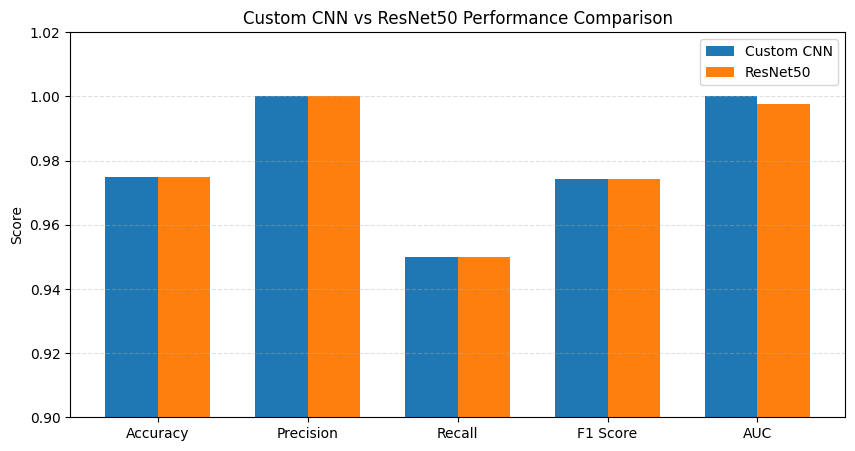

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC']

cnn_scores = [
    cnn_accuracy,
    cnn_precision,
    cnn_recall,
    cnn_f1,
    cnn_auc
]

resnet_scores = [
    0.9750,
    1.0000,
    0.9500,
    0.9744,
    0.9975
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, cnn_scores, width, label='Custom CNN')
plt.bar(x + width/2, resnet_scores, width, label='ResNet50')

plt.ylabel('Score')
plt.title('Custom CNN vs ResNet50 Performance Comparison')
plt.xticks(x, metrics)
plt.ylim(0.90, 1.02)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.show()

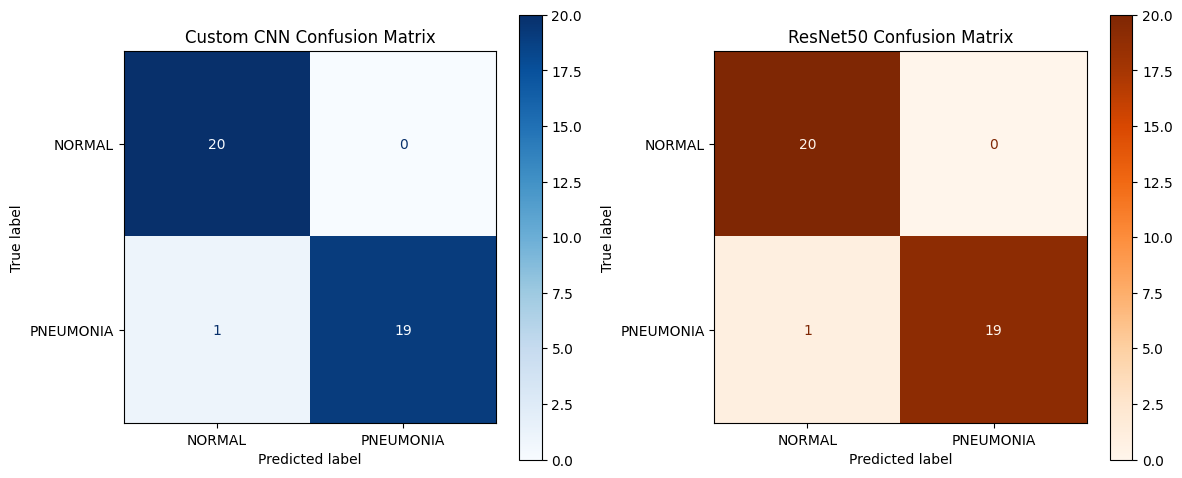

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrices
cm_cnn = confusion_matrix(y_true, cnn_pred)
cm_resnet = confusion_matrix(y_true, y_pred)

# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=['NORMAL', 'PNEUMONIA']
).plot(ax=axes[0], cmap='Blues', values_format='d')

axes[0].set_title('Custom CNN Confusion Matrix')

ConfusionMatrixDisplay(
    confusion_matrix=cm_resnet,
    display_labels=['NORMAL', 'PNEUMONIA']
).plot(ax=axes[1], cmap='Oranges', values_format='d')

axes[1].set_title('ResNet50 Confusion Matrix')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print("========== CUSTOM CNN ==========")
print(classification_report(
    y_true,
    cnn_pred,
    target_names=['NORMAL', 'PNEUMONIA']
))

print("========== RESNET50 ==========")
print(classification_report(
    y_true,
    y_pred,
    target_names=['NORMAL', 'PNEUMONIA']
))

========== CUSTOM CNN ==========
              precision    recall  f1-score   support

      NORMAL       0.95      1.00      0.98        20
   PNEUMONIA       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40

========== RESNET50 ==========
              precision    recall  f1-score   support

      NORMAL       0.95      1.00      0.98        20
   PNEUMONIA       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40



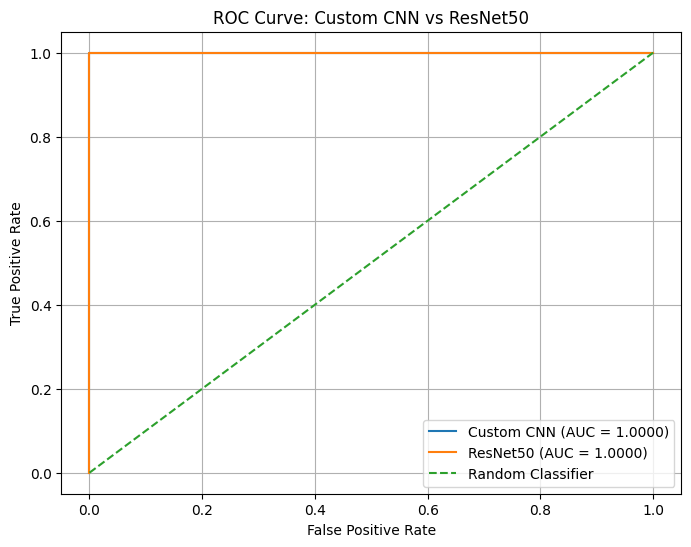

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Calculate ROC curves
fpr_cnn, tpr_cnn, _ = roc_curve(
    y_true, cnn_pred_prob.flatten()
)

fpr_resnet, tpr_resnet, _ = roc_curve(
    y_true, y_pred_prob.flatten()
)

auc_cnn = auc(fpr_cnn, tpr_cnn)
auc_resnet = auc(fpr_resnet, tpr_resnet)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_cnn, tpr_cnn,
    label=f'Custom CNN (AUC = {auc_cnn:.4f})'
)

plt.plot(
    fpr_resnet, tpr_resnet,
    label=f'ResNet50 (AUC = {auc_resnet:.4f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Custom CNN vs ResNet50')
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Saving the best model
cnn_model.save("custom_cnn_model.keras")


print("Model saved successfully!")

Model saved successfully!


In [ ]:
# ==========================================
# CUSTOM CNN ARCHITECTURE CHECK
# ==========================================

cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 327,941 (1.25 MB)

 Trainable params: 109,313 (427.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 218,628 (854.02 KB)